In [ ]:

# Step 1: Install required package
%pip install -q ucimlrepo

# Step 2: Import libraries
import pandas as pd
from ucimlrepo import fetch_ucirepo

# Step 3: Load the Concrete Compressive Strength dataset
concrete = fetch_ucirepo(id=165)

# Step 4: Separate inputs (X) and target (y)
X = concrete.data.features
y = concrete.data.targets

# Step 5: Check the dataset dimensions
print("Input data shape:", X.shape)
print("Target data shape:", y.shape)

# Step 6: Display the first five samples
display(X.head())


Input data shape: (1030, 8)
Target data shape: (1030, 1)


,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360


In [ ]:

# Combine input features and target
df = X.copy()
df["Strength"] = y.iloc[:, 0].to_numpy()

# Check dataset information
print("=== Dataset Information ===")
df.info()

# Check missing values
print("\n=== Missing Values ===")
print(df.isnull().sum())

# Check duplicate rows
print("\n=== Duplicate Rows ===")
print(df.duplicated().sum())

# Descriptive statistics
print("\n=== Descriptive Statistics ===")
display(df.describe().T)


=== Dataset Information ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Cement              1030 non-null   float64
 1   Blast Furnace Slag  1030 non-null   float64
 2   Fly Ash             1030 non-null   float64
 3   Water               1030 non-null   float64
 4   Superplasticizer    1030 non-null   float64
 5   Coarse Aggregate    1030 non-null   float64
 6   Fine Aggregate      1030 non-null   float64
 7   Age                 1030 non-null   int64  
 8   Strength            1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB

=== Missing Values ===
Cement                0
Blast Furnace Slag    0
Fly Ash               0
Water                 0
Superplasticizer      0
Coarse Aggregate      0
Fine Aggregate        0
Age                   0
Strength              0
dtype: int64

=== Duplicate Rows ===

,count,mean,std,min,25%,50%,75%,max
Cement,1030.0,281.167864,104.506364,102.00,192.375,272.900,350.000,540.0
Blast Furnace Slag,1030.0,73.895825,86.279342,0.00,0.000,22.000,142.950,359.4
Fly Ash,1030.0,54.188350,63.997004,0.00,0.000,0.000,118.300,200.1
Water,1030.0,181.567282,21.354219,121.80,164.900,185.000,192.000,247.0
Superplasticizer,1030.0,6.204660,5.973841,0.00,0.000,6.400,10.200,32.2
Coarse Aggregate,1030.0,972.918932,77.753954,801.00,932.000,968.000,1029.400,1145.0
Fine Aggregate,1030.0,773.580485,80.175980,594.00,730.950,779.500,824.000,992.6
Age,1030.0,45.662136,63.169912,1.00,7.000,28.000,56.000,365.0
Strength,1030.0,35.817961,16.705742,2.33,23.710,34.445,46.135,82.6


In [ ]:

# Step 2.2: Examine duplicated observations

duplicate_rows = df[df.duplicated(keep=False)]

print("Repeated rows beyond first occurrence:",
      df.duplicated().sum())

print("Total rows involved in duplicates:",
      len(duplicate_rows))

display(duplicate_rows.head(15))


Repeated rows beyond first occurrence: 25
Total rows involved in duplicates: 36


,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
72,425.0,106.3,0.0,153.5,16.5,852.1,887.1,3,33.40
77,425.0,106.3,0.0,153.5,16.5,852.1,887.1,3,33.40
80,425.0,106.3,0.0,153.5,16.5,852.1,887.1,3,33.40
83,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.30
86,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.30
88,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.30
91,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.30
95,425.0,106.3,0.0,153.5,16.5,852.1,887.1,7,49.20
100,425.0,106.3,0.0,153.5,16.5,852.1,887.1,7,49.20
103,425.0,106.3,0.0,153.5,16.5,852.1,887.1,7,49.20


In [ ]:

# Remove exact duplicate rows
df_clean = df.drop_duplicates().reset_index(drop=True)

# Check the results
print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)
print("Remaining duplicates:",
      df_clean.duplicated().sum())

# Separate features and target
X_clean = df_clean.drop(columns=["Strength"])
y_clean = df_clean["Strength"]


Original dataset: (1030, 9)
Cleaned dataset: (1005, 9)
Remaining duplicates: 0


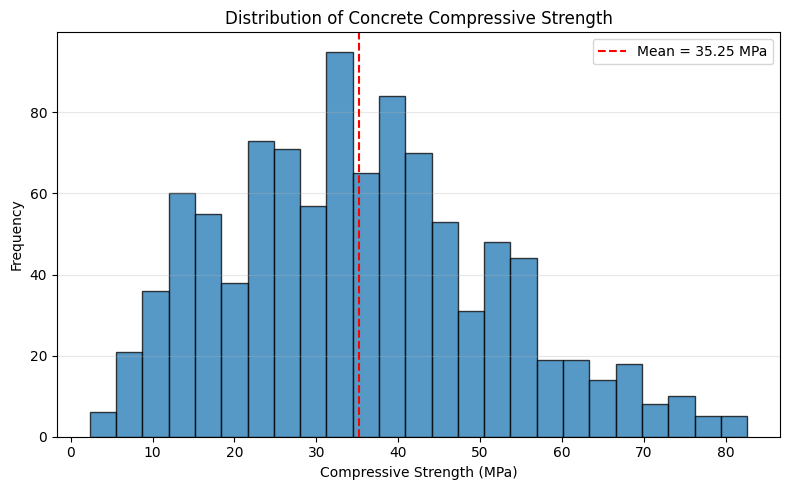

In [ ]:

import matplotlib.pyplot as plt

# Plot strength distribution
plt.figure(figsize=(8, 5))

plt.hist(
    df_clean["Strength"],
    bins=25,
    edgecolor="black",
    alpha=0.75
)

# Add mean strength line
mean_strength = df_clean["Strength"].mean()

plt.axvline(
    mean_strength,
    color="red",
    linestyle="--",
    label=f"Mean = {mean_strength:.2f} MPa"
)

plt.xlabel("Compressive Strength (MPa)")
plt.ylabel("Frequency")
plt.title("Distribution of Concrete Compressive Strength")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


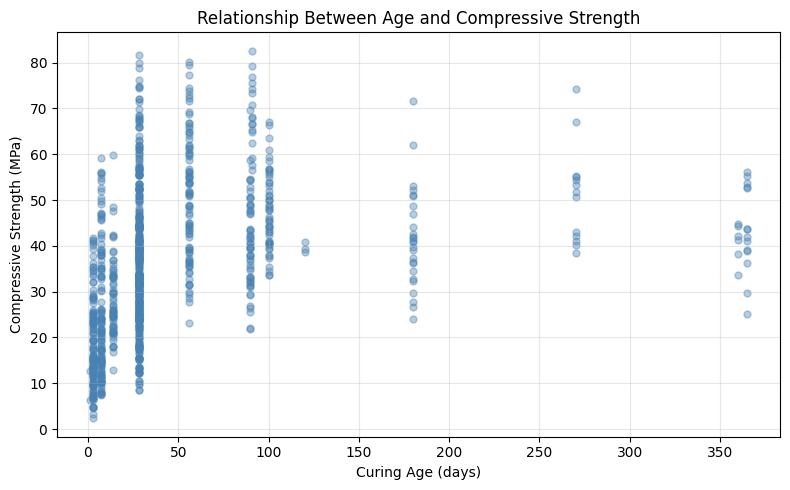

In [ ]:

import matplotlib.pyplot as plt

# Age vs. compressive strength
plt.figure(figsize=(8, 5))

plt.scatter(
    df_clean["Age"],
    df_clean["Strength"],
    alpha=0.4,
    s=25,
    color="steelblue"
)

plt.xlabel("Curing Age (days)")
plt.ylabel("Compressive Strength (MPa)")
plt.title("Relationship Between Age and Compressive Strength")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


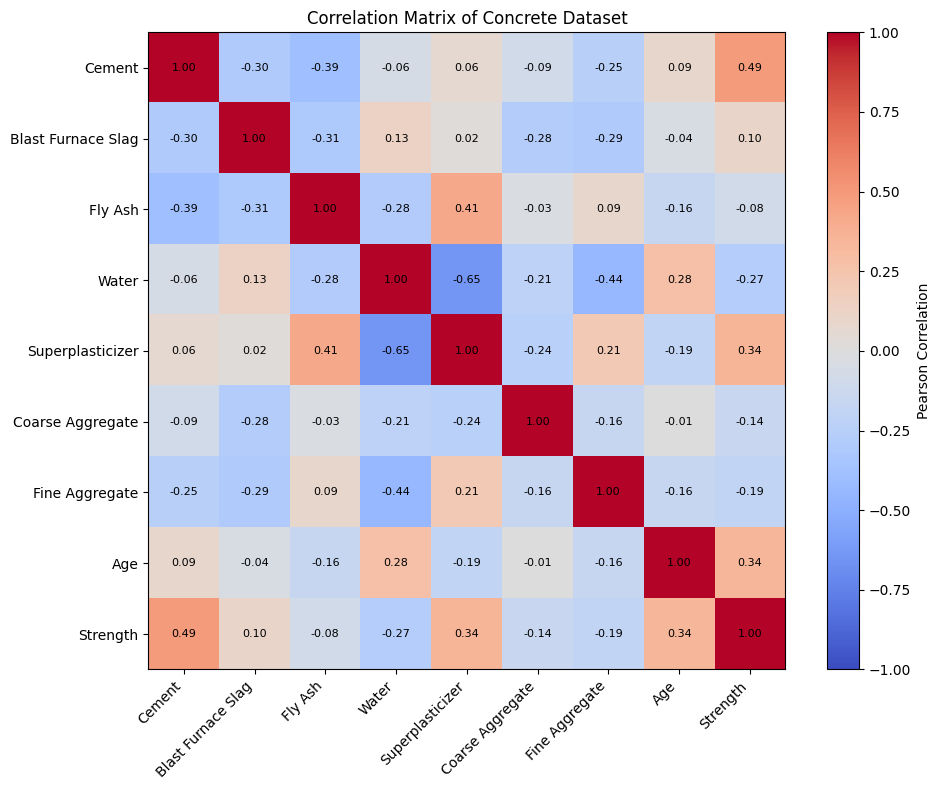

Correlation with Strength:
Strength              1.000000
Cement                0.488283
Superplasticizer      0.344209
Age                   0.337367
Blast Furnace Slag    0.103374
Fly Ash              -0.080648
Coarse Aggregate     -0.144717
Fine Aggregate       -0.186448
Water                -0.269624
Name: Strength, dtype: float64


In [ ]:

import matplotlib.pyplot as plt
import numpy as np

# Step 2.5: Pearson Correlation Analysis
corr_matrix = df_clean.corr(method="pearson")

# Plot correlation heatmap
fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(
    corr_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

# Axis labels
ax.set_xticks(range(len(corr_matrix.columns)))
ax.set_yticks(range(len(corr_matrix.columns)))

ax.set_xticklabels(
    corr_matrix.columns,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(corr_matrix.columns)

# Display correlation coefficients
for i in range(len(corr_matrix)):
    for j in range(len(corr_matrix)):
        value = corr_matrix.iloc[i, j]
        ax.text(
            j, i, f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )

plt.colorbar(im, ax=ax, label="Pearson Correlation")
plt.title("Correlation Matrix of Concrete Dataset")
plt.tight_layout()
plt.show()

# Correlation with compressive strength
print("Correlation with Strength:")
print(
    corr_matrix["Strength"]
    .sort_values(ascending=False)
)


In [ ]:

# Step 3.3: Evaluate Linear Regression

import numpy as np
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

print("=== Linear Regression Results ===")
print(f"MAE:  {mae_lr:.4f} MPa")
print(f"RMSE: {rmse_lr:.4f} MPa")
print(f"R²:   {r2_lr:.4f}")


NameError: name 'y_test' is not defined

In [ ]:

# Step 3: Linear Regression

import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 1. Prepare features and target
X_clean = df_clean.drop(columns=["Strength"])
y_clean = df_clean["Strength"]

# 2. Split dataset (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(
    X_clean,
    y_clean,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

# 3. Train Linear Regression model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# 4. Predict test data
y_pred_lr = lr_model.predict(X_test)

# 5. Evaluate model
mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

print("\n=== Linear Regression Results ===")
print(f"MAE:  {mae_lr:.4f} MPa")
print(f"RMSE: {rmse_lr:.4f} MPa")
print(f"R²:   {r2_lr:.4f}")


Training samples: 804
Testing samples: 201

=== Linear Regression Results ===
MAE:  8.8953 MPa
RMSE: 11.1913 MPa
R²:   0.5802


In [ ]:

# Step 4: Random Forest Regression

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# 1. Initialize Random Forest
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# 2. Train the model
rf_model.fit(X_train, y_train)

# 3. Predict test data
y_pred_rf = rf_model.predict(X_test)

# 4. Evaluate model performance
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

# 5. Display results
print("=== Random Forest Results ===")
print(f"MAE:  {mae_rf:.4f} MPa")
print(f"RMSE: {rmse_rf:.4f} MPa")
print(f"R²:   {r2_rf:.4f}")


=== Random Forest Results ===
MAE:  3.5329 MPa
RMSE: 5.2034 MPa
R²:   0.9092


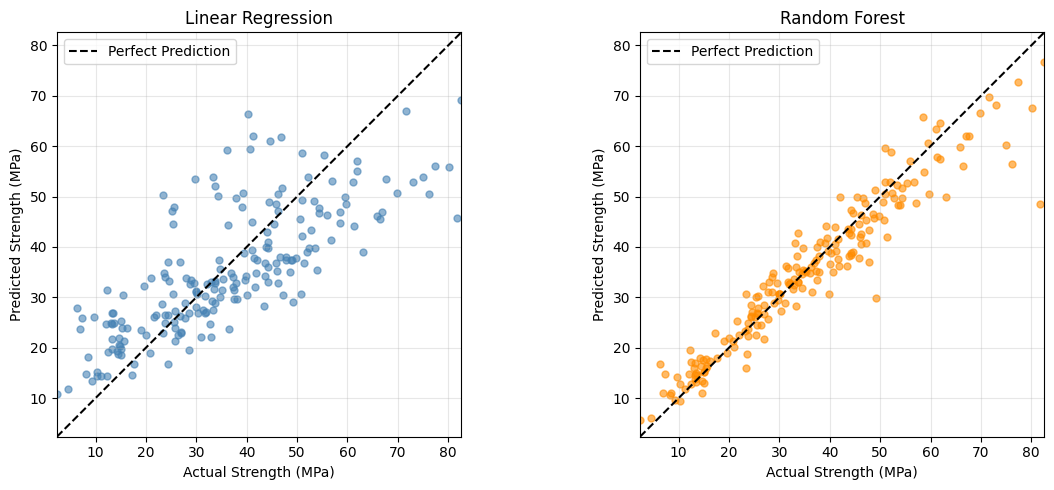

In [ ]:

# Step 5: Actual vs Predicted Strength

import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

models = [
    ("Linear Regression", y_pred_lr, "steelblue"),
    ("Random Forest", y_pred_rf, "darkorange")
]

lower = min(y_test.min(), y_pred_lr.min(), y_pred_rf.min())
upper = max(y_test.max(), y_pred_lr.max(), y_pred_rf.max())

for ax, (name, prediction, color) in zip(axes, models):

    ax.scatter(
        y_test,
        prediction,
        alpha=0.6,
        s=25,
        color=color
    )

    # Ideal prediction line
    ax.plot(
        [lower, upper],
        [lower, upper],
        "k--",
        linewidth=1.5,
        label="Perfect Prediction"
    )

    ax.set_xlim(lower, upper)
    ax.set_ylim(lower, upper)
    ax.set_aspect("equal", adjustable="box")

    ax.set_xlabel("Actual Strength (MPa)")
    ax.set_ylabel("Predicted Strength (MPa)")
    ax.set_title(name)

    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()

# Save figure for final report
plt.savefig(
    "Actual_vs_Predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:

# Step 6: Check model overfitting

import pandas as pd
import numpy as np

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Training predictions
y_train_pred_lr = lr_model.predict(X_train)
y_train_pred_rf = rf_model.predict(X_train)

# Evaluation function
def evaluate_model(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

# Compare training and testing results
comparison = pd.DataFrame({
    "Linear Regression - Train":
        evaluate_model(y_train, y_train_pred_lr),

    "Linear Regression - Test":
        evaluate_model(y_test, y_pred_lr),

    "Random Forest - Train":
        evaluate_model(y_train, y_train_pred_rf),

    "Random Forest - Test":
        evaluate_model(y_test, y_pred_rf)
}).T

display(comparison.round(4))


,MAE,RMSE,R2
Linear Regression - Train,7.9599,10.0018,0.6099
Linear Regression - Test,8.8953,11.1913,0.5802
Random Forest - Train,1.3471,2.0196,0.9841
Random Forest - Test,3.5329,5.2034,0.9092


In [ ]:

# Step 7: Group-based Train-Test Split

import pandas as pd
import numpy as np

from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Group samples using mixture composition
# Age is excluded because the same mix may
# be tested at different curing ages.
mix_cols = [c for c in X_clean.columns if c != "Age"]

groups = X_clean.groupby(
    mix_cols, sort=False
).ngroup()

# Split by mixture groups (not individual rows)
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X_clean, y_clean, groups=groups)
)

X_g_train = X_clean.iloc[train_idx]
X_g_test = X_clean.iloc[test_idx]

y_g_train = y_clean.iloc[train_idx]
y_g_test = y_clean.iloc[test_idx]

# Check whether any mixture group overlaps
train_groups = set(groups.iloc[train_idx])
test_groups = set(groups.iloc[test_idx])

print("Number of unique mixtures:", groups.nunique())
print("Training samples:", len(X_g_train))
print("Testing samples:", len(X_g_test))
print(
    "Overlapping mixture groups:",
    len(train_groups.intersection(test_groups))
)

# Train the same two models
lr_group = LinearRegression()
rf_group = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

lr_group.fit(X_g_train, y_g_train)
rf_group.fit(X_g_train, y_g_train)

# Evaluate on unseen mixture groups
def evaluate(y_true, pred):
    return [
        mean_absolute_error(y_true, pred),
        np.sqrt(mean_squared_error(y_true, pred)),
        r2_score(y_true, pred)
    ]

group_results = pd.DataFrame(
    [
        evaluate(y_g_test, lr_group.predict(X_g_test)),
        evaluate(y_g_test, rf_group.predict(X_g_test))
    ],
    index=["Linear Regression", "Random Forest"],
    columns=["MAE (MPa)", "RMSE (MPa)", "R2"]
)

print("\n=== Group-based Test Results ===")
display(group_results.round(4))


Number of unique mixtures: 427
Training samples: 800
Testing samples: 205
Overlapping mixture groups: 0

=== Group-based Test Results ===


,MAE (MPa),RMSE (MPa),R2
Linear Regression,8.4762,10.7238,0.6372
Random Forest,4.1752,6.0067,0.8862


=== Permutation Feature Importance ===


,Feature,Importance,Std
7,Age,8.0929,0.4998
0,Cement,6.5059,0.3590
1,Blast Furnace Slag,1.9965,0.2246
3,Water,1.8249,0.2170
4,Superplasticizer,1.1911,0.1476
6,Fine Aggregate,0.7376,0.1132
5,Coarse Aggregate,0.5106,0.0825
2,Fly Ash,0.1718,0.0653


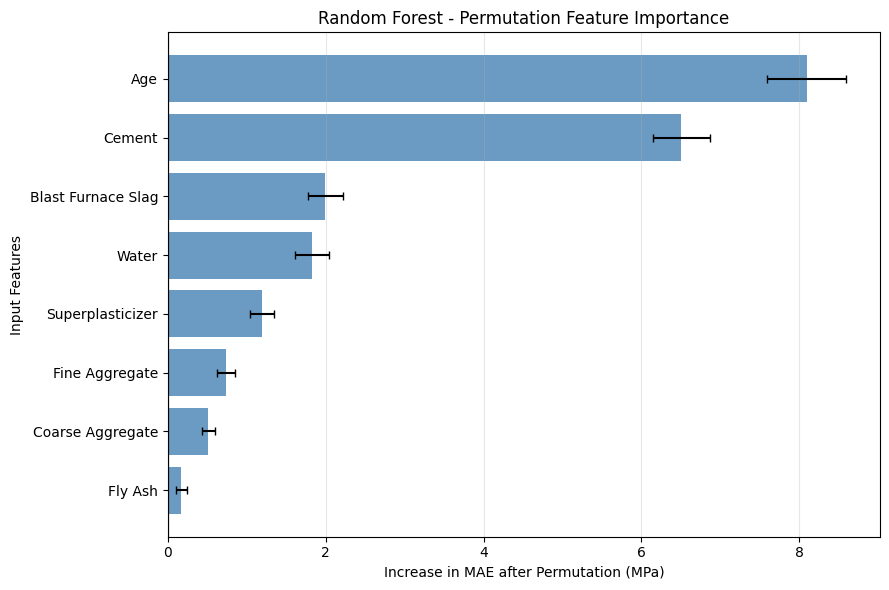

In [ ]:

# Step 8: Permutation Feature Importance

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

# Calculate permutation importance
perm_result = permutation_importance(
    rf_group,
    X_g_test,
    y_g_test,
    n_repeats=10,
    random_state=42,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

# Organize results
importance_df = pd.DataFrame({
    "Feature": X_g_test.columns,
    "Importance": perm_result.importances_mean,
    "Std": perm_result.importances_std
})

# Sort features
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("=== Permutation Feature Importance ===")
display(importance_df.round(4))

# Plot importance
plot_df = importance_df.sort_values("Importance")

plt.figure(figsize=(9, 6))

plt.barh(
    plot_df["Feature"],
    plot_df["Importance"],
    xerr=plot_df["Std"],
    color="steelblue",
    alpha=0.8,
    capsize=3
)

plt.axvline(0, color="black", linewidth=0.8)

plt.xlabel("Increase in MAE after Permutation (MPa)")
plt.ylabel("Input Features")
plt.title("Random Forest - Permutation Feature Importance")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "Feature_Importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:

# Step 9: Group-based 5-Fold Cross-Validation

import pandas as pd
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Identify unique concrete mixture groups
mix_cols = [c for c in X_clean.columns if c != "Age"]

groups = X_clean.groupby(
    mix_cols, sort=False
).ngroup()

# Define cross-validation
cv = GroupKFold(n_splits=5)

# Models
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=1
    )
}

# Evaluation metrics
scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

results_cv = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_clean,
        y_clean,
        groups=groups,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    results_cv.append({
        "Model": name,
        "MAE Mean": -scores["test_MAE"].mean(),
        "MAE Std": scores["test_MAE"].std(),
        "RMSE Mean": -scores["test_RMSE"].mean(),
        "R2 Mean": scores["test_R2"].mean(),
        "R2 Std": scores["test_R2"].std()
    })

cv_df = pd.DataFrame(results_cv)

print("=== 5-Fold Group Cross-Validation ===")
display(cv_df.round(4))


=== 5-Fold Group Cross-Validation ===


,Model,MAE Mean,MAE Std,RMSE Mean,R2 Mean,R2 Std
0,Linear Regression,8.2417,0.1765,10.4033,0.5834,0.0571
1,Random Forest,4.4147,0.3023,6.1461,0.8534,0.0338


In [ ]:

# Step 10.2: Predict new concrete strength

import pandas as pd
import joblib

# Load saved model
package = joblib.load("concrete_rf_model.joblib")

loaded_model = package["model"]
feature_names = package["features"]

# New concrete mixture (illustrative example)
new_concrete = pd.DataFrame([{
    "Cement": 300,
    "Blast Furnace Slag": 100,
    "Fly Ash": 0,
    "Water": 180,
    "Superplasticizer": 6,
    "Coarse Aggregate": 1000,
    "Fine Aggregate": 800,
    "Age": 28
}])

# Ensure correct feature order
new_concrete = new_concrete[feature_names]

# Predict compressive strength
predicted_strength = loaded_model.predict(new_concrete)

print(
    f"Predicted Compressive Strength: "
    f"{predicted_strength[0]:.2f} MPa"
)


FileNotFoundError: [Errno 2] No such file or directory: 'concrete_rf_model.joblib'

In [ ]:

import os

print("Current directory:", os.getcwd())

print("Model file exists:",
      os.path.exists("concrete_rf_model.joblib"))


Current directory: /content
Model file exists: False


In [ ]:

# Step 10: Train, Save, Load and Predict

import pandas as pd
import joblib
import os
from sklearn.ensemble import RandomForestRegressor

# 1. Prepare cleaned dataset
X_clean = df_clean.drop(columns=["Strength"])
y_clean = df_clean["Strength"]

# 2. Train final Random Forest model
final_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

final_model.fit(X_clean, y_clean)

print("Model training completed!")

# 3. Save model
model_package = {
    "model": final_model,
    "features": X_clean.columns.tolist()
}

joblib.dump(model_package, "concrete_rf_model.joblib")

print("Model saved successfully!")
print("Saved path:",
      os.path.abspath("concrete_rf_model.joblib"))

# 4. Load model
package = joblib.load("concrete_rf_model.joblib")

loaded_model = package["model"]
feature_names = package["features"]

print("Model loaded successfully!")

# 5. Example concrete mixture
new_concrete = pd.DataFrame([{
    "Cement": 300,
    "Blast Furnace Slag": 100,
    "Fly Ash": 0,
    "Water": 180,
    "Superplasticizer": 6,
    "Coarse Aggregate": 1000,
    "Fine Aggregate": 800,
    "Age": 28
}])

new_concrete = new_concrete[feature_names]

# 6. Predict compressive strength
prediction = loaded_model.predict(new_concrete)

print("\n=== Prediction Result ===")
print(f"Predicted Strength: {prediction[0]:.2f} MPa")


Model training completed!
Model saved successfully!
Saved path: /content/concrete_rf_model.joblib
Model loaded successfully!

=== Prediction Result ===
Predicted Strength: 41.19 MPa


In [ ]:

from google.colab import files

files.download("concrete_rf_model.joblib")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from google.colab import files
import os

figure_files = [
    "Actual_vs_Predicted.png",
    "Feature_Importance.png"
]

for filename in figure_files:
    if os.path.exists(filename):
        files.download(filename)
    else:
        print(f"File not found: {filename}")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>